# Touchless Presentation Control Using Hand Gestures
An English-language machine-learning university project.

**Research question:** How do a custom CNN, frozen MobileNetV2 transfer learning, and training augmentation compare on hand gestures from unseen people?

The interface includes a built-in presentation, practice mode, command history, stable-gesture confirmation, and a cooldown. It does not send keyboard events to unrelated applications.

**Commands:** palm → next slide; fist → previous slide; thumbs up → start; peace → toggle pointer; neutral hand → no command. Low scores also mean no command, but are not a validated unknown-object detector.

Run on a Colab GPU with **Runtime → Run all**. Camera access is requested only when you click the camera button in the demo. Keep one hand inside the guide. No perfect recognition or security/liveness guarantee is claimed.

## 1. Environment and reproducibility
The dataset is a downscaled, third-party HaGRID sample. We preserve attribution and save the source revision and experiment configuration. It is a computational subset study, not the full HaGRID benchmark.

In [ ]:
import sys, subprocess, importlib.util
for package in ['requests', 'ipywidgets']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import os, io, json, time, random, hashlib, zipfile, gc, platform
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import tensorflow as tf
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Javascript
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers
OUT=Path('/content/gesture_project'); OUT.mkdir(exist_ok=True)
SEED=42
RUN_SEEDS=[42,123]
SIZE=96
EPOCHS=6
BATCH=32
MAX_PER_CLASS=800
CLASSES=['palm','fist','like','peace','no_gesture']
DISPLAY_NAMES=['Open palm','Closed fist','Thumbs up','Peace / two fingers','Neutral hand']
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
config=dict(seed=SEED,run_seeds=RUN_SEEDS,image_size=SIZE,epochs=EPOCHS,batch_size=BATCH,max_per_class=MAX_PER_CLASS,classes=CLASSES)
(OUT/'config.json').write_text(json.dumps(config,indent=2))
print('TensorFlow:',tf.__version__,'| GPU:',tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download and inspect the dataset
Source: https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p
Original dataset: https://github.com/hukenovs/hagrid
The sample card lists CC BY-SA 4.0. Preserve source attribution and review the original license for redistribution. We use no demographic attributes and perform no identity recognition.

In [ ]:
DATA_URL='https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p/resolve/40b00da/hagrid-sample-30k-384p.zip'
archive=OUT/'hagrid_sample.zip'
if not archive.exists():
    partial=archive.with_suffix('.partial')
    with requests.get(DATA_URL,stream=True,timeout=(30,180)) as response:
        response.raise_for_status()
        total=int(response.headers.get('content-length',0)); received=0; last=time.monotonic()
        with partial.open('wb') as f:
            for block in response.iter_content(1024*1024):
                if block:
                    f.write(block); received+=len(block)
                    if time.monotonic()-last>10:
                        print(f'Downloaded {received/1e6:.0f} MB'+(f' / {total/1e6:.0f} MB' if total else ''),flush=True); last=time.monotonic()
    partial.rename(archive)
with zipfile.ZipFile(archive) as z:
    names=z.namelist()
    print('Archive files:',len(names))
    print('Sample paths:',names[:8])
    annotations=[n for n in names if n.lower().endswith('.json')]
    print('Annotation files:',annotations[:25])
    print('Annotation schema: normalized [x,y,width,height] boxes, labels, and person IDs.')
(OUT/'dataset_source.json').write_text(json.dumps(dict(url=DATA_URL,archive_sha256=hashlib.sha256(archive.read_bytes()).hexdigest()),indent=2))

## 3. Data preparation and controlled training
We sample up to 800 hand crops per class: open palm, fist, thumbs up (`like`), peace, and neutral hand (`no_gesture`). Annotated neutral hands are not a complete representation of unknown objects or empty backgrounds.

A crop uses the annotated hand box with 10% context on each side. We audit exact crop duplicates before splitting. We split by **person ID** and verify that neither people nor original source images cross train/validation/test. The split proportions are approximate because whole people stay together. Crop images are resized to 96 × 96 RGB pixels. The same crops and splits are used in all models.

**Models:**
- Custom CNN: three Conv2D/ReLU/MaxPooling blocks (24, 48, 96 filters), global average pooling, Dense(64, ReLU), Dropout(0.3), and five-way Softmax.
- MobileNetV2: frozen ImageNet backbone, global average pooling, the same hidden/output head design, and model-internal rescaling to [-1,1].
- MobileNetV2 + augmentation: same frozen backbone and classifier, with rotation, translation, zoom and contrast changes during training only.

**Training:** seeds 42 and 123, six epochs each, Adam learning rate 0.001, batch size 32. Select the minimum validation-loss checkpoint. Paired MobileNet heads have identical initial weights and data order. The CNN comparison measures architecture/pretraining under a fixed epoch budget, not equal compute. Two seeds are exploratory repeats, not K-fold cross-validation.

**Theory:** ReLU introduces nonlinearity while retaining a positive-side gradient. Softmax produces a normalized five-class score vector. Sparse categorical cross-entropy uses integer targets and is equivalent to categorical cross-entropy with one-hot labels. Backpropagation computes gradients and Adam updates trainable parameters. Frozen backbone weights are not updated; this is feature extraction, not fine-tuning.

PASS: no person, source image, or exact crop crosses splits.


gesture,fist,like,no_gesture,palm,peace
split,,,,,
test,175,159,153,170,166
train,500,502,526,510,496
validation,125,139,121,120,138


,Distinct people
split,
test,431
train,1376
validation,344


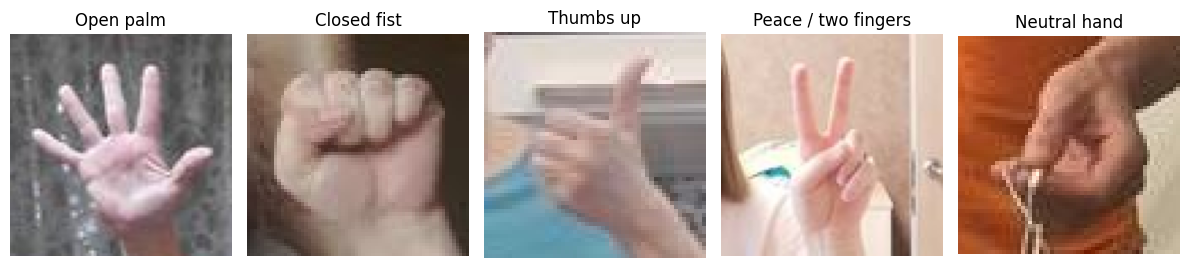


Training CNN, seed 42
Epoch 1/6
80/80 - 8s - 98ms/step - accuracy: 0.2407 - loss: 1.5858 - val_accuracy: 0.2504 - val_loss: 1.5331
Epoch 2/6
80/80 - 2s - 20ms/step - accuracy: 0.3015 - loss: 1.5150 - val_accuracy: 0.3297 - val_loss: 1.5082
Epoch 3/6
80/80 - 2s - 21ms/step - accuracy: 0.3106 - loss: 1.5005 - val_accuracy: 0.2862 - val_loss: 1.5196
Epoch 4/6
80/80 - 2s - 21ms/step - accuracy: 0.3331 - loss: 1.4776 - val_accuracy: 0.2908 - val_loss: 1.4849
Epoch 5/6
80/80 - 2s - 21ms/step - accuracy: 0.3418 - loss: 1.4703 - val_accuracy: 0.3515 - val_loss: 1.4668
Epoch 6/6
80/80 - 2s - 20ms/step - accuracy: 0.3394 - loss: 1.4583 - val_accuracy: 0.3484 - val_loss: 1.4565
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training MobileNet, seed 42
Epoch 1/6
80/80 - 8s - 102ms/step - accuracy: 0.7727 - loss: 0.6464 - val_accuracy: 0.9082 - val_loss: 0.2733
Epoch 2/6
80/80 - 3s - 33ms/step - accuracy: 0.9219 - loss: 0.2368 - val_accuracy: 0.9362 - val_loss: 0.2051
Epoch 3/6
80/80 - 2s - 30m

In [ ]:
# Build hand crops with an identity-disjoint split.
with zipfile.ZipFile(archive) as z:
    image_files={Path(n).stem:n for n in z.namelist() if n.lower().endswith(('.jpg','.jpeg','.png'))}
    annotation_map={}
    for name in z.namelist():
        if name.lower().endswith('.json'):
            obj=json.loads(z.read(name))
            if isinstance(obj,dict):
                for key,value in obj.items():
                    if isinstance(value,dict) and 'bboxes' in value and 'labels' in value:
                        annotation_map[Path(key).stem]=value
    if not annotation_map:
        raise ValueError('No supported HaGRID annotations found. Inspect the dataset structure above.')
    candidates=[]
    for image_id,ann in annotation_map.items():
        if image_id not in image_files or not ann.get('user_id'):
            continue
        for j,(box,label) in enumerate(zip(ann['bboxes'],ann['labels'])):
            if label in CLASSES and len(box)==4 and box[2]>0 and box[3]>0:
                candidates.append((image_id,j,label,str(ann['user_id']),box))
    random.Random(SEED).shuffle(candidates)
    counts={k:0 for k in CLASSES}; seen={}; records=[]; crop_dir=OUT/'crops'; crop_dir.mkdir(exist_ok=True)
    for image_id,j,label,person,box in candidates:
        if counts[label]>=MAX_PER_CLASS: continue
        with Image.open(io.BytesIO(z.read(image_files[image_id]))) as im:
            im=im.convert('RGB'); w,h=im.size; x,y,bw,bh=box
            # Square crop with 10% context, matching the live square guide.
            side=max(bw*w,bh*h)*1.2; cx=(x+bw/2)*w; cy=(y+bh/2)*h
            left=max(0,int(cx-side/2)); top=max(0,int(cy-side/2))
            right=min(w,int(cx+side/2)); bottom=min(h,int(cy+side/2))
            if right<=left or bottom<=top: continue
            crop=im.crop((left,top,right,bottom))
            digest=hashlib.sha256(str(crop.size).encode()+crop.tobytes()).hexdigest()
            if digest in seen:
                if seen[digest]!=label: raise ValueError('Identical crop has conflicting gesture labels')
                continue
            seen[digest]=label
            path=crop_dir/f'{image_id}_{j}.png'; crop.save(path)
        records.append(dict(path=str(path),label=CLASSES.index(label),gesture=label,person=person,image_id=image_id,pixel_sha256=digest))
        counts[label]+=1
    frame=pd.DataFrame(records)
assert all(counts[c]>=100 for c in CLASSES), f'Insufficient class counts: {counts}'
# Random group split is selected solely from person IDs, never from model results.
trainval_idx,test_idx=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(frame,groups=frame.person))
trainval=frame.iloc[trainval_idx]
train_rel,val_rel=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED+1).split(trainval,groups=trainval.person))
frame['split']='test'
frame.loc[trainval.index[train_rel],'split']='train'
frame.loc[trainval.index[val_rel],'split']='validation'
for split in ['train','validation','test']:
    assert set(frame.loc[frame.split==split,'label'])==set(range(len(CLASSES)))
    other=frame.loc[frame.split!=split]
    assert not set(frame.loc[frame.split==split,'person']) & set(other.person)
    assert not set(frame.loc[frame.split==split,'image_id']) & set(other.image_id)
frame.to_csv(OUT/'split_manifest.csv',index=False)
print('PASS: no person, source image, or exact crop crosses splits.')
display(pd.crosstab(frame.split,frame.gesture))
display(frame.groupby('split').person.nunique().rename('Distinct people'))
parts={s:frame[frame.split==s].reset_index(drop=True) for s in ['train','validation','test']}
fig,axes=plt.subplots(1,5,figsize=(12,3))
for k,ax in enumerate(axes):
    sample=parts['train'][parts['train'].label==k].iloc[0]
    ax.imshow(Image.open(sample.path)); ax.set_title(DISPLAY_NAMES[k]); ax.axis('off')
plt.tight_layout(); plt.show()

def load_crop(path,label):
    x=tf.io.decode_png(tf.io.read_file(path),channels=3)
    return tf.image.resize(tf.cast(x,tf.float32),[SIZE,SIZE]), tf.cast(label,tf.int32)
def dataset(split,seed=SEED,training=False):
    rows=parts[split]
    ds=tf.data.Dataset.from_tensor_slices((rows.path.tolist(),rows.label.to_numpy()))
    if training: ds=ds.shuffle(len(rows),seed=seed,reshuffle_each_iteration=True)
    options=tf.data.Options(); options.experimental_deterministic=True
    return ds.with_options(options).map(load_crop,num_parallel_calls=tf.data.AUTOTUNE,deterministic=True).batch(BATCH).prefetch(tf.data.AUTOTUNE)
def augmentation(seed):
    return tf.keras.Sequential([layers.RandomRotation(.06,seed=seed+11),layers.RandomTranslation(.08,.08,seed=seed+12),layers.RandomZoom(.1,seed=seed+13),layers.RandomContrast(.15,seed=seed+14)],name='training_augmentation')
def build_gesture_model(kind,seed):
    tf.keras.utils.set_random_seed(seed)
    inp=layers.Input((SIZE,SIZE,3),name='hand_crop_rgb'); x=inp
    if kind=='MobileNet_aug': x=augmentation(seed)(x)
    if kind=='CNN':
        x=layers.Rescaling(1/255.)(x)
        for filters in [24,48,96]:
            x=layers.Conv2D(filters,3,padding='same',activation='relu')(x)
            x=layers.MaxPooling2D()(x)
    else:
        x=layers.Rescaling(1/127.5,offset=-1)(x)
        base=tf.keras.applications.MobileNetV2(input_shape=(SIZE,SIZE,3),include_top=False,weights='imagenet')
        base.trainable=False
        x=base(x,training=False)
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.Dense(64,activation='relu',kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed+101),name='hidden')(x)
    x=layers.Dropout(.3,seed=seed+102)(x)
    out=layers.Dense(len(CLASSES),activation='softmax',kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed+103),name='gesture_scores')(x)
    m=tf.keras.Model(inp,out,name=kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return m
val_ds=dataset('validation'); test_ds=dataset('test')
training_records=[]; histories={}; paired_weights={}
for seed in RUN_SEEDS:
    for kind in ['CNN','MobileNet','MobileNet_aug']:
        tf.keras.backend.clear_session(); gc.collect()
        model=build_gesture_model(kind,seed)
        if kind.startswith('MobileNet'):
            digest=hashlib.sha256(b''.join(w.tobytes() for name in ['hidden','gesture_scores'] for w in model.get_layer(name).get_weights())).hexdigest()
            if kind=='MobileNet': paired_weights[seed]=digest
            else: assert digest==paired_weights[seed], 'A/B initial classifier weights differ'
        checkpoint=OUT/f'{kind}_{seed}.keras'
        print(f'\nTraining {kind}, seed {seed}',flush=True)
        start=time.perf_counter()
        hist=model.fit(dataset('train',seed,True),validation_data=val_ds,epochs=EPOCHS,verbose=2,
                       callbacks=[tf.keras.callbacks.ModelCheckpoint(str(checkpoint),monitor='val_loss',save_best_only=True)])
        duration=time.perf_counter()-start
        table=pd.DataFrame(hist.history); table.to_csv(OUT/f'history_{kind}_{seed}.csv',index=False)
        histories[(kind,seed)]=table
        best=int(table.val_loss.argmin())
        training_records.append(dict(model=kind,seed=seed,best_epoch=best+1,best_val_loss=float(table.val_loss.iloc[best]),training_seconds=duration,checkpoint=str(checkpoint)))
        del model
pd.DataFrame(training_records).to_csv(OUT/'training_records.csv',index=False)
print('PASS: all training runs complete; paired MobileNet classifiers started identically.')


## 4. Held-out evaluation and validation-only deployment selection
Report every run, test cross-entropy, accuracy, macro F1, confusion matrices and learning curves. The test set contains only people excluded from development. We do not tune epochs, models, or score gates using test results.

For the interface, choose the lowest-validation-loss model among seed-42 runs. Select a score gate from validation data: at least 20 accepted gesture commands, at least 90% accepted-command accuracy, and at most 5% false commands on neutral hands. If no gate qualifies, automatic commands stay disabled. This engineering gate is not probability calibration or reliable detection of unknown objects.

Inference timing below is model-only. The interface separately measures browser-to-result delay. Single-image test accuracy does not establish camera command accuracy or false commands per minute.

,model,seed,best_epoch,best_val_loss,training_seconds,accuracy,macro_f1,test_loss
0,CNN,42,6,1.456455,18.647824,0.385176,0.361371,1.477670
1,MobileNet,42,5,0.159920,20.988552,0.938032,0.937295,0.186105
2,MobileNet_aug,42,5,0.170215,23.252685,0.929526,0.928158,0.190097
3,CNN,123,6,1.457821,12.567835,0.363305,0.346729,1.474541
4,MobileNet,123,6,0.134633,21.496437,0.935601,0.934814,0.176793
5,MobileNet_aug,123,6,0.198220,21.557012,0.936817,0.936101,0.193853


accuracy            macro_f1           test_loss          
                   mean       std      mean       std      mean       std
model                                                                    
CNN            0.374241  0.015465  0.354050  0.010353  1.476106  0.002213
MobileNet      0.936817  0.001718  0.936054  0.001754  0.181449  0.006585
MobileNet_aug  0.933171  0.005155  0.932130  0.005617  0.191975  0.002656

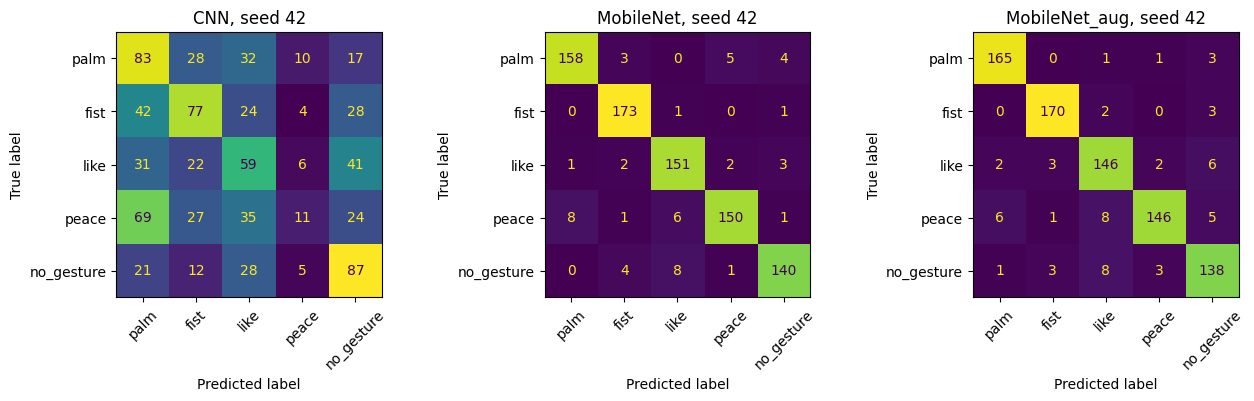

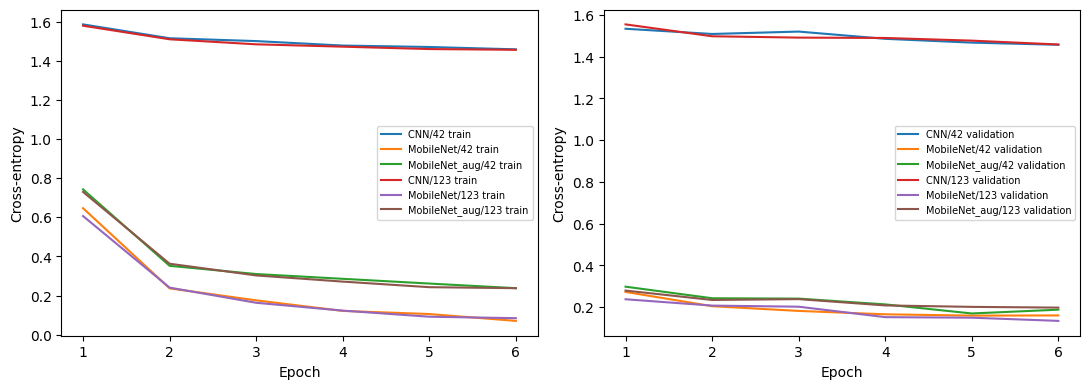

Demo model selected using validation loss: ('MobileNet', 42)
Validation-selected command score gate: 0.5
Median model-only inference: 144.1 ms (not camera-to-command latency)
PASS: evaluations complete. No model or threshold was selected using test accuracy.


In [ ]:
results=[]; predictions={}; validation_predictions={}
truth=parts['test'].label.to_numpy(); val_truth=parts['validation'].label.to_numpy()
for record in training_records:
    tf.keras.backend.clear_session(); gc.collect()
    model=tf.keras.models.load_model(record['checkpoint'],compile=False)
    scores=model.predict(test_ds,verbose=0); val_scores=model.predict(val_ds,verbose=0)
    assert scores.shape==(len(truth),len(CLASSES))
    np.testing.assert_allclose(scores.sum(axis=1),1,atol=1e-5)
    pred=scores.argmax(axis=1); key=(record['model'],record['seed'])
    predictions[key]=scores; validation_predictions[key]=val_scores
    loss=float(tf.keras.losses.sparse_categorical_crossentropy(truth,scores).numpy().mean())
    results.append({**record,'accuracy':accuracy_score(truth,pred),'macro_f1':f1_score(truth,pred,average='macro'),'test_loss':loss})
    pd.DataFrame({'path':parts['test'].path,'truth':truth,'prediction':pred,**{c:scores[:,i] for i,c in enumerate(CLASSES)}}).to_csv(OUT/f'predictions_{key[0]}_{key[1]}.csv',index=False)
    (OUT/f'report_{key[0]}_{key[1]}.json').write_text(json.dumps(classification_report(truth,pred,target_names=CLASSES,output_dict=True,zero_division=0),indent=2))
    del model
results_df=pd.DataFrame(results); results_df.to_csv(OUT/'test_results.csv',index=False)
display(results_df.drop(columns='checkpoint'))
display(results_df.groupby('model')[['accuracy','macro_f1','test_loss']].agg(['mean','std']))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,kind in zip(axes,['CNN','MobileNet','MobileNet_aug']):
    ConfusionMatrixDisplay.from_predictions(truth,predictions[(kind,SEED)].argmax(1),labels=list(range(5)),display_labels=CLASSES,ax=ax,colorbar=False,xticks_rotation=45)
    ax.set_title(f'{kind}, seed {SEED}')
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for (kind,seed),h in histories.items():
    axes[0].plot(np.arange(1,len(h)+1),h.loss,label=f'{kind}/{seed} train')
    axes[1].plot(np.arange(1,len(h)+1),h.val_loss,label=f'{kind}/{seed} validation')
for ax in axes: ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png',dpi=160); plt.show()
# The demo model is chosen by validation loss at the predetermined first seed.
eligible=[r for r in training_records if r['seed']==SEED]
deployment_record=min(eligible,key=lambda r:r['best_val_loss'])
deployment_key=(deployment_record['model'],SEED)
deployment_model=tf.keras.models.load_model(deployment_record['checkpoint'],compile=False)
v=validation_predictions[deployment_key]; vp=v.argmax(1); vc=v.max(1)
threshold_records=[]
for threshold in np.arange(.5,1.,.025):
    accept=(vc>=threshold)&(vp!=4)
    precision=float((vp[accept]==val_truth[accept]).mean()) if accept.any() else 0.
    neutral=val_truth==4
    false_rate=float(accept[neutral].mean()) if neutral.any() else float('nan')
    threshold_records.append(dict(threshold=float(threshold),command_precision=precision,neutral_false_command_rate=false_rate,accepted_command_fraction=float(accept.mean()),accepted_count=int(accept.sum())))
gates=pd.DataFrame(threshold_records)
qualified=gates[(gates.command_precision>=.9)&(gates.neutral_false_command_rate<=.05)&(gates.accepted_count>=20)]
COMMAND_THRESHOLD=float(qualified.iloc[0].threshold) if len(qualified) else 1.01
(OUT/'validation_gate_audit.csv').write_text(gates.to_csv(index=False))
(OUT/'deployment.json').write_text(json.dumps(dict(**deployment_record,command_threshold=COMMAND_THRESHOLD,policy='Validation command precision >= .90, neutral false-command rate <= .05, at least 20 accepted commands; otherwise commands disabled'),indent=2))
print('Demo model selected using validation loss:',deployment_key)
print('Validation-selected command score gate:',COMMAND_THRESHOLD)
if COMMAND_THRESHOLD>1: print('No validation gate met the criteria. Practice mode works; automatic gesture commands remain disabled.')
# Runtime latency excludes webcam, serialization, browser and network delays.
probe=next(iter(test_ds))[0][:1]; deployment_model(probe,training=False)
latencies=[]
for _ in range(20):
    tick=time.perf_counter(); deployment_model(probe,training=False).numpy(); latencies.append((time.perf_counter()-tick)*1000)
print(f'Median model-only inference: {np.median(latencies):.1f} ms (not camera-to-command latency)')
# Keep exact data and model provenance available for the final report.
(OUT/'environment.json').write_text(json.dumps(dict(python=platform.python_version(),tensorflow=tf.__version__,numpy=np.__version__,gpu=[d.name for d in tf.config.list_physical_devices('GPU')]),indent=2))
print('PASS: evaluations complete. No model or threshold was selected using test accuracy.')


## 5. Interactive presentation and practice lab
Run this cell after training/evaluation, or rerun it after reconnecting the interface. You can test labeled examples and tightly cropped hand uploads without a camera.

**Camera:** click Start camera and grant access only when you choose. Keep one hand inside the square guide. Predictions use the trained model in your connected Colab runtime. No video recording and no public server are implemented.

**Commands:** enable the checkbox, then hold a gesture for at least 700 ms and three observations. There is a 1,400 ms cooldown. Relax your hand to repeat the same gesture. A 2,000 ms observation gap restarts the hold. Use the labeled replay button to test the actual prediction-to-command path without a camera; replay events are marked separately from live camera events.

The built-in presentation is editable. It does not control external PowerPoint or Google Slides. The two-finger gesture toggles the pointer; the pointer follows mouse movement, not tracked fingertips. Use Stop camera to release the device and disable commands.

Gesture,Model score

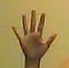
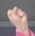
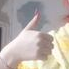
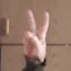
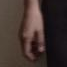

PASS: app backend matches saved predictions for all five representative crops.


In [6]:
import base64
from google.colab import output
from IPython.display import JSON

def gesture_predict(data_url):
    try:
        if not isinstance(data_url,str) or len(data_url)>15_000_000:
            raise ValueError('Invalid image payload')
        raw=base64.b64decode(data_url.split(',',1)[1],validate=True)
        image=tf.io.decode_image(raw,channels=3,expand_animations=False)
        if int(tf.size(image))>30_000_000: raise ValueError('Image is too large')
        image=tf.image.resize(tf.cast(image,tf.float32),[SIZE,SIZE])[None]
        start=time.perf_counter(); scores=deployment_model(image,training=False).numpy()[0]
        elapsed=(time.perf_counter()-start)*1000
        return JSON(dict(scores=[float(v) for v in scores],model_ms=elapsed))
    except (ValueError,tf.errors.OpError) as error:
        return JSON(dict(error=str(error)[:250]))
output.register_callback('gesture_control.predict',gesture_predict)
# Exactly one predetermined test crop per class, not selected for correctness.
samples=[]
for k in range(len(CLASSES)):
    row=parts['test'][parts['test'].label==k].iloc[0]
    raw=Path(row.path).read_bytes()
    data_url='data:image/png;base64,'+base64.b64encode(raw).decode()
    result=gesture_predict(data_url).data
    np.testing.assert_allclose(result['scores'],predictions[deployment_key][row.name],rtol=1e-4,atol=1e-5)
    samples.append(dict(name=f'{DISPLAY_NAMES[k]} — known test label',image=data_url))
config_demo=dict(model=f"{deployment_record['model']} / seed {SEED}",threshold=COMMAND_THRESHOLD,classes=CLASSES,names=DISPLAY_NAMES,samples=samples,slides=[
    dict(title='Touchless Presentation Control',body='A hand-gesture classification project.\nResearch question: how do architecture and augmentation affect generalization to unseen people?'),
    dict(title='Data and leakage controls',body=f"HaGRID hand crops: {len(frame)} images.\nPeople and source images are disjoint across train, validation, and test.\nFive classes include neutral hands."),
    dict(title='Models and lecture theory',body='Custom CNN vs frozen MobileNetV2, with and without augmentation.\nReLU, convolution, pooling, Softmax and cross-entropy.\nBackpropagation and validation checkpoint selection.'),
    dict(title='Measured results',body='Mean test accuracy across two seeds:\n'+'\n'.join(f"{kind}: {100*value:.1f}%" for kind,value in results_df.groupby('model').accuracy.mean().items())+'\nTwo repeats are exploratory, not a guarantee of generalization.'),
    dict(title='Control and limitations',body='Stable hold, minimum frames, neutral release and cooldown.\nClass predictions are not verified confidence probabilities.\nLive camera accuracy and accidental commands require a separate user study.')])
# Inline app source is inserted by the project builder. No public server or hidden API key.
APP_HTML = '<style>\n.gesture-app{font:15px system-ui,sans-serif;color:#162135;max-width:1050px;margin:12px auto;line-height:1.5}.gesture-app *{box-sizing:border-box}.gesture-app h2{font-size:28px;margin:0}.gesture-app h3{margin:18px 0 8px}.gesture-app p{margin:7px 0}.gesture-app button,.gesture-app select,.gesture-app input{font:inherit;max-width:100%}.gesture-app button{padding:10px 14px;border:1px solid #cbd5e1;border-radius:8px;background:white;color:#17243a;cursor:pointer}.gesture-app button.primary{background:#1e40af;color:white;border:0}.gesture-app button:disabled{opacity:.5;cursor:wait}.gesture-app .tools{display:flex;gap:8px;flex-wrap:wrap;margin:12px 0}.gesture-app .notice{background:#eef4ff;border-left:4px solid #365fd7;padding:12px}.gesture-app .columns{display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:22px}.gesture-app .stage{position:relative;min-width:0;background:#111b2a;border-radius:12px;overflow:hidden}.gesture-app video{width:100%;display:block;transform:scaleX(-1)}.gesture-app .guide{position:absolute;left:50%;top:50%;width:60%;height:60%;transform:translate(-50%,-50%);border:2px dashed #67e8f9;pointer-events:none}.gesture-app .preview{width:100%;max-height:240px;object-fit:contain;display:none;background:#eef2f7}.gesture-app .status{font-size:17px;font-weight:650;padding:10px 0}.gesture-app .muted{color:#526174;font-size:13px}.gesture-app table{width:100%;border-collapse:collapse}.gesture-app th,.gesture-app td{text-align:left;padding:6px;border-bottom:1px solid #e2e8f0}.gesture-app .slides{position:relative;background:#172b4c;color:#fff;min-height:260px;padding:30px;border-radius:12px;margin-top:14px}.gesture-app .slides h3{color:#fff!important;font-size:28px;margin:10px 0}.gesture-app .slide-body{white-space:pre-line;font-size:18px}.gesture-app .pointer{position:absolute;width:16px;height:16px;background:#fbbf24;border:2px solid #fff;border-radius:50%;left:50%;top:50%;display:none;pointer-events:none}.gesture-app textarea{width:100%;min-height:130px;font:14px system-ui}.gesture-app summary{cursor:pointer;font-weight:600}.gesture-app .history{max-height:160px;overflow:auto;font-size:13px}.gesture-app .meter{height:5px;background:#e5eaf2}.gesture-app .meter span{display:block;height:100%;background:#237c87}.gesture-app .error{color:#b42318}@media(max-width:650px){.gesture-app .columns{grid-template-columns:1fr}.gesture-app h2{font-size:23px}.gesture-app .slides{padding:18px}}\n</style>\n<div class="gesture-app" id="gesture-app">\n<h2>Touchless Presentation Control</h2>\n<p>Hand gestures, measured experiments, and a presentation you can control.</p>\n<div class="notice">Start in <b>Practice mode</b>. Put one hand inside the cyan square. Hold a gesture for at least 0.7 seconds and three predictions. Relax your hand before repeating the same command.</div>\n<p class="muted" id="model-info"></p>\n<div class="tools"><button id="start-camera" class="primary">Start camera</button><button id="stop-camera">Stop camera</button><label><input type="checkbox" id="enable-commands"> Enable presentation commands</label></div>\n<p class="muted">Camera starts only on your request. Cropped frames go to your connected Colab runtime for prediction; this app does not record video or start a public server. Stop camera when finished.</p>\n<div class="columns"><section>\n<div class="stage" id="camera-stage"><video id="camera" autoplay playsinline muted></video><div class="guide"></div></div>\n<img class="preview" id="image-preview" alt="Selected hand crop">\n<div class="status" id="prediction-status" role="status" aria-live="polite">Ready. Try a labeled example below, or start your camera.</div>\n<div class="meter"><span id="hold-progress" style="width:0%"></span></div>\n<p class="muted" id="latency"></p>\n<table aria-label="Gesture scores"><thead><tr><th>Gesture</th><th>Model score</th></tr></thead><tbody id="score-rows"></tbody></table>\n</section><section>\n<h3>Practice without a camera</h3><label for="sample-select">Labeled test example</label><br><select id="sample-select"></select>\n<div class="tools"><button id="predict-sample" class="primary">Predict example</button><button id="replay-sample">Replay held gesture (test)</button></div>\n<label for="image-upload">Or upload a tightly cropped hand photo</label><br><input id="image-upload" type="file" accept="image/png,image/jpeg">\n<p class="muted">Uploaded photos are center-cropped to a square. A whole-body photo will not match the hand-crop training task.</p>\n<details><summary>Command mapping and limits</summary><p>Open palm: next slide<br>Closed fist: previous slide<br>Thumbs up: start presentation<br>Peace / two fingers: toggle pointer<br>Neutral hand: no command</p><p>Unknown objects may still receive high scores. This is not liveness detection or a security system. Neutral hands are trained; arbitrary backgrounds and all unseen gestures are not.</p></details>\n<h3>Session log</h3><div class="tools"><button id="mark-accidental">Mark last command accidental</button><button id="export-log">Download session log</button></div>\n<div class="history" id="command-history" aria-live="polite">No commands yet.</div>\n<p class="muted" id="session-stats">Single-image practice does not change slides. Replay tests can send commands when enabled.</p>\n</section></div>\n<h3>Your presentation</h3>\n<div class="tools"><button id="start-slides">Start slides</button><button id="previous-slide">Previous</button><button id="next-slide">Next</button><button id="pointer-button">Toggle pointer</button><button id="fullscreen-slides">Fullscreen</button></div>\n<div id="slide-stage" class="slides"><small id="slide-number"></small><h3 id="slide-title"></h3><div id="slide-body" class="slide-body"></div><span class="pointer" id="slide-pointer"></span></div>\n<p class="muted">Commands control this built-in presentation. The pointer follows your mouse when visible. External PowerPoint / Google Slides are not controlled.</p>\n<details><summary>Edit presentation text</summary><p>One slide per line. Separate its title and body with a vertical bar.</p><textarea id="slide-editor"></textarea><button id="apply-slides">Apply slides</button></details>\n<p class="muted" id="check-status"></p>\n</div>\n<script>\n(async()=>{\nconst cfg=__CONFIG__;\n__CONTROLLER__\nconst root=document.getElementById(\'gesture-app\');\nconst el=id=>root.querySelector(\'#\'+id);\nlet stream=null,running=false,busy=false,sessionStart=null,selectedImage=null;\nlet currentSlide=0,started=false,pointer=false,commandCount=0;\nconst events=[];const gate=new GestureGate();\nconst slides=cfg.slides.map(s=>({...s}));\nconst names=cfg.names;\nel(\'model-info\').textContent=`Model: ${cfg.model}. Validation-selected command score gate: ${cfg.threshold<=1?cfg.threshold.toFixed(3):\'disabled (validation criteria not met)\'}. Scores are uncalibrated. ${cfg.threshold>1?\'Only manual slide buttons are enabled.\':\'\'}`;\nfor(let i=0;i<cfg.samples.length;i++){const opt=document.createElement(\'option\');opt.value=i;opt.textContent=cfg.samples[i].name;el(\'sample-select\').append(opt);}\nfunction renderSlides(){el(\'slide-number\').textContent=started?`Slide ${currentSlide+1} of ${slides.length}`:\'Presentation ready\';el(\'slide-title\').textContent=started?slides[currentSlide].title:\'Ready when you are\';el(\'slide-body\').textContent=started?slides[currentSlide].body:\'Use Start slides, or enable commands and hold thumbs up.\';el(\'slide-pointer\').style.display=pointer?\'block\':\'none\';}\nfunction execute(label,source=\'gesture\'){\n let action=\'\';if(label===\'like\'){started=true;currentSlide=0;action=\'Start presentation\';}\n else if(label===\'palm\'&&started){currentSlide=Math.min(slides.length-1,currentSlide+1);action=\'Next slide\';}\n else if(label===\'fist\'&&started){currentSlide=Math.max(0,currentSlide-1);action=\'Previous slide\';}\n else if(label===\'peace\'&&started){pointer=!pointer;action=\'Toggle pointer\';}\n if(!action)return;renderSlides();\n const event={type:\'command\',time:new Date().toISOString(),gesture:label,action,source,slide:currentSlide+1,accidental:false};events.push(event);\n if(source===\'gesture\')commandCount++;\n renderLog();\n}\nfunction renderLog(){const commands=events.filter(e=>e.type===\'command\');el(\'command-history\').replaceChildren();for(const e of commands.slice(-12).reverse()){const p=document.createElement(\'p\');p.textContent=`${new Date(e.time).toLocaleTimeString(\'en-GB\',{timeZone:\'Asia/Seoul\'})} · ${e.action} · ${e.source}${e.accidental?\' · MARKED ACCIDENTAL\':\'\'}`;el(\'command-history\').append(p);}\n const elapsed=sessionStart?(performance.now()-sessionStart)/60000:0;const accidental=commands.filter(e=>e.source===\'gesture\'&&e.accidental).length;\n el(\'session-stats\').textContent=`Gesture commands: ${commandCount}. Manually marked accidental: ${accidental}. Active session: ${elapsed.toFixed(1)} min. This is a session observation, not a controlled accuracy estimate.`;\n}\nasync function predict(dataURL,source){\n if(busy)return;busy=true;el(\'predict-sample\').disabled=true;const tick=performance.now();\n try{\n  const response=await google.colab.kernel.invokeFunction(\'gesture_control.predict\',[dataURL],{});\n  const data=response.data[\'application/json\'];if(data.error)throw Error(data.error);\n  const order=data.scores.map((v,i)=>[v,i]).sort((a,b)=>b[0]-a[0]);const [score,index]=order[0];\n  el(\'prediction-status\').textContent=`${names[index]} · score ${score.toFixed(3)}${source===\'camera\'?\'\':\' · single-image practice\'}`;\n  el(\'latency\').textContent=`Model: ${data.model_ms.toFixed(0)} ms. Browser-to-result: ${(performance.now()-tick).toFixed(0)} ms (includes communication).`;\n  el(\'score-rows\').replaceChildren();for(const [value,i] of order){const row=document.createElement(\'tr\');for(const text of [names[i],value.toFixed(3)]){const td=document.createElement(\'td\');td.textContent=text;row.append(td);}el(\'score-rows\').append(row);}\n  if(source===\'camera\'||source===\'replay\'){\n   const now=performance.now();const command=gate.update(cfg.classes[index],score,now,cfg.threshold);\n   el(\'hold-progress\').style.width=gate.candidate?Math.min(100,(now-gate.since)/gate.holdMs*100)+\'%\':\'0%\';\n   if(command&&el(\'enable-commands\').checked)execute(command,source===\'replay\'?\'replay\':\'gesture\');\n  }else{gate.reset();el(\'hold-progress\').style.width=\'0%\';}\n }catch(error){el(\'prediction-status\').textContent=\'Prediction unavailable: \'+error.message+\'. Check the Colab connection and rerun the demo cell if needed.\';gate.reset();}\n finally{busy=false;el(\'predict-sample\').disabled=false;}\n}\nfunction stopCamera(){running=false;if(stream)stream.getTracks().forEach(t=>t.stop());stream=null;el(\'camera\').srcObject=null;gate.reset();el(\'start-camera\').disabled=false;el(\'enable-commands\').checked=false;renderLog();}\nasync function cameraLoop(){\n if(!running)return;\n const v=el(\'camera\');if(v.videoWidth&&!busy){const side=Math.min(v.videoWidth,v.videoHeight)*.6;const canvas=document.createElement(\'canvas\');canvas.width=224;canvas.height=224;canvas.getContext(\'2d\').drawImage(v,(v.videoWidth-side)/2,(v.videoHeight-side)/2,side,side,0,0,224,224);await predict(canvas.toDataURL(\'image/jpeg\',.9),\'camera\');}\n if(running)setTimeout(cameraLoop,180);\n}\nel(\'start-camera\').onclick=async()=>{try{if(running)return;stream=await navigator.mediaDevices.getUserMedia({video:{width:640,height:480},audio:false});el(\'camera\').srcObject=stream;await el(\'camera\').play();el(\'image-preview\').style.display=\'none\';running=true;sessionStart=performance.now();el(\'start-camera\').disabled=true;gate.reset();cameraLoop();}catch(error){stopCamera();el(\'prediction-status\').textContent=\'Camera unavailable: \'+error.message+\'. You can still use labeled examples and image uploads.\';}};\nel(\'stop-camera\').onclick=stopCamera;\nfunction updateGuide(){const video=el(\'camera\');const side=Math.min(video.clientWidth,video.clientHeight)*.6;const guide=root.querySelector(\'.guide\');guide.style.width=side+\'px\';guide.style.height=side+\'px\';}\nnew ResizeObserver(updateGuide).observe(el(\'camera-stage\'));\nel(\'camera\').onloadedmetadata=updateGuide;\nel(\'replay-sample\').onclick=async()=>{if(running||busy){el(\'prediction-status\').textContent=\'Stop the camera and wait for prediction before replaying.\';return;}el(\'replay-sample\').disabled=true;const sample=cfg.samples[Number(el(\'sample-select\').value)];el(\'image-preview\').src=sample.image;el(\'image-preview\').style.display=\'block\';gate.reset();for(let i=0;i<4;i++){await predict(sample.image,\'replay\');await new Promise(resolve=>setTimeout(resolve,300));}el(\'replay-sample\').disabled=false;};\nel(\'enable-commands\').onchange=()=>{gate.reset();if(!sessionStart)sessionStart=performance.now();};\nel(\'predict-sample\').onclick=async()=>{stopCamera();const sample=cfg.samples[Number(el(\'sample-select\').value)];el(\'image-preview\').src=sample.image;el(\'image-preview\').style.display=\'block\';await predict(sample.image,\'example\');};\nel(\'image-upload\').onchange=async event=>{stopCamera();const f=event.target.files[0];if(!f)return;if(f.size>10*1024*1024){el(\'prediction-status\').textContent=\'Choose a JPEG/PNG under 10 MB.\';return;}\n try{const url=URL.createObjectURL(f);const image=new Image();await new Promise((resolve,reject)=>{image.onload=resolve;image.onerror=reject;image.src=url;});const canvas=document.createElement(\'canvas\');canvas.width=224;canvas.height=224;const s=Math.min(image.width,image.height);canvas.getContext(\'2d\').drawImage(image,(image.width-s)/2,(image.height-s)/2,s,s,0,0,224,224);URL.revokeObjectURL(url);const data=canvas.toDataURL(\'image/jpeg\',.95);el(\'image-preview\').src=data;el(\'image-preview\').style.display=\'block\';await predict(data,\'upload\');}catch(error){el(\'prediction-status\').textContent=\'Could not decode this image.\';}};\nel(\'start-slides\').onclick=()=>execute(\'like\',\'manual\');el(\'previous-slide\').onclick=()=>execute(\'fist\',\'manual\');el(\'next-slide\').onclick=()=>execute(\'palm\',\'manual\');el(\'pointer-button\').onclick=()=>execute(\'peace\',\'manual\');\nel(\'fullscreen-slides\').onclick=()=>{const stage=el(\'slide-stage\');if(stage.requestFullscreen)stage.requestFullscreen().catch(()=>{el(\'prediction-status\').textContent=\'Fullscreen is unavailable in this embedded view.\';});};\nel(\'slide-stage\').onmousemove=event=>{const r=el(\'slide-stage\').getBoundingClientRect();el(\'slide-pointer\').style.left=(event.clientX-r.left)+\'px\';el(\'slide-pointer\').style.top=(event.clientY-r.top)+\'px\';};\nel(\'mark-accidental\').onclick=()=>{const last=[...events].reverse().find(e=>e.type===\'command\'&&e.source===\'gesture\');if(last){last.accidental=true;renderLog();}else el(\'session-stats\').textContent=\'No gesture command to mark yet.\';};\nel(\'export-log\').onclick=()=>{const blob=new Blob([JSON.stringify({model:cfg.model,threshold:cfg.threshold,events},null,2)],{type:\'application/json\'});const link=document.createElement(\'a\');link.href=URL.createObjectURL(blob);link.download=\'gesture_session_log.json\';link.click();setTimeout(()=>URL.revokeObjectURL(link.href),1000);};\nel(\'slide-editor\').value=slides.map(s=>s.title+\' | \'+s.body.replace(/\\n/g,\' \')).join(\'\\n\');\nel(\'apply-slides\').onclick=()=>{const replacement=el(\'slide-editor\').value.split(\'\\n\').filter(s=>s.trim()).map(s=>{const pos=s.indexOf(\'|\');return{title:pos<0?s:s.slice(0,pos).trim(),body:pos<0?\'\':s.slice(pos+1).trim()};});if(replacement.length){slides.splice(0,slides.length,...replacement);currentSlide=0;started=false;renderSlides();}};\nwindow.addEventListener(\'pagehide\',stopCamera);\n// A controller check exercises the same stable-hold path used for camera commands.\nconst testGate=new GestureGate();const checks=[];checks.push(testGate.update(\'palm\',.99,0,.8)===null);checks.push(testGate.update(\'palm\',.99,350,.8)===null);checks.push(testGate.update(\'palm\',.99,750,.8)===\'palm\');checks.push(testGate.update(\'palm\',.99,1500,.8)===null);\nel(\'check-status\').textContent=checks.every(Boolean)?\'Controller checks passed: stable hold, minimum frames, and no repeat while holding.\':\'Controller check failed.\';\nrenderSlides();\n})();\n</script>\n'
CONTROLLER_SOURCE = "class GestureGate {\n  constructor({holdMs=700,cooldownMs=1400,minFrames=3,maxGapMs=2000}={}) {\n    Object.assign(this,{holdMs,cooldownMs,minFrames,maxGapMs}); this.reset();\n  }\n  reset(){this.candidate=null;this.since=0;this.frames=0;this.latched=null;this.lastFire=-Infinity;this.lastTime=-Infinity;}\n  update(label,score,now,threshold){\n    if(now-this.lastTime>this.maxGapMs){this.candidate=null;this.frames=0;this.latched=null;}\n    this.lastTime=now;\n    if(label==='no_gesture'||score<threshold){this.candidate=null;this.frames=0;this.latched=null;return null;}\n    if(label!==this.candidate){this.candidate=label;this.since=now;this.frames=1;}\n    else this.frames++;\n    if(this.latched===label||now-this.since<this.holdMs||this.frames<this.minFrames||now-this.lastFire<this.cooldownMs)return null;\n    this.latched=label;this.lastFire=now;return label;\n  }\n}\nif(typeof module!=='undefined')module.exports={GestureGate};\n"
rendered=APP_HTML.replace('__CONFIG__',json.dumps(config_demo).replace('</','<\\/')).replace('__CONTROLLER__',CONTROLLER_SOURCE)
display(HTML(rendered))
print('PASS: app backend matches saved predictions for all five representative crops.')


## 6. Actual results and interpretation
This executed run used **4,000 hand crops**: 2,534 training, 643 validation, and 823 test crops, with 1,376 / 344 / 431 distinct people respectively.

| Model | Mean test accuracy | Seed SD (percentage points) | Mean macro F1 |
|---|---:|---:|---:|
| Custom CNN | 37.42% | 1.55 | 0.3541 |
| MobileNetV2 | 93.68% | 0.17 | 0.9361 |
| MobileNetV2 + augmentation | 93.32% | 0.52 | 0.9321 |

These are results of the two recorded seeds, not promised future scores. Re-running on a different environment may differ. The small CNN's low training and validation accuracy indicates underfitting under this budget. More epochs or a different custom architecture could change the comparison. The augmentation difference is small and does not establish that augmentation is generally harmful.

The runtime-selected model is MobileNetV2, seed 42, chosen by validation loss. This is a fixed-budget subset experiment, not a comparison to published full-HaGRID results.

### Lecture connections
| Lecture | Implemented concepts |
|---|---|
| 01 | Supervised multiclass classification |
| 02 | Neural layers, ReLU and nonlinear activation |
| 03 | Softmax, cross-entropy, gradient optimization and backpropagation |
| 04 | Underfitting, overfitting and generalization |
| 06 | Convolution, padding, pooling and held-out validation |
| 07 | Transfer learning, MobileNet depthwise/pointwise convolution |
| 08 | Training-only image augmentation |

Lecture 05's regression/Ridge/Lasso and KNN are not implemented. Repeated seeds must not be described as K-fold validation.

### Limitations and a separate live study
The app assumes one tightly framed hand. It does not perform automatic hand detection, identity recognition or liveness verification. Hand-crop test performance may not transfer to full webcam scenes. High Softmax scores can occur for unknown objects. Exact duplicates and person-disjoint splits do not rule out near duplicates, label errors or pretraining overlap.

Live camera accuracy, response time, missed commands and accidental commands require a separate evaluation with consenting people excluded from development. Log intended commands, successful commands and neutral intervals. Static practice/replay checks do not substitute for a camera study. This live study is **not yet performed**, and no results are invented.

### References and submission
- HaGRID authors and paper: https://github.com/hukenovs/hagrid and https://arxiv.org/abs/2206.08219
- Christian Mills, downscaled HaGRID sample: https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p, revision 40b00da. Dataset card: CC BY-SA 4.0. Preserve attribution and applicable license terms when redistributing crops.
- MobileNetV2: https://arxiv.org/abs/1801.04381
- TensorFlow transfer learning: https://www.tensorflow.org/tutorials/images/transfer_learning

The dataset URL, archive hash, split manifest, checkpoints, environment and CSV results are saved in `/content/gesture_project`. Report AI assistance according to your course policy. Verify any separate professor rubric and submission format; these lecture decks did not provide a complete assignment rubric.

## 7. Optional artifact download
Set the flag below to True only when you want a download. This bundles the model checkpoints, experiment configuration, manifests and results, excluding the original dataset archive and crop images. Colab runtime storage is temporary. Keep this archive if you need the trained weights later.

In [ ]:
DOWNLOAD_PROJECT_ARTIFACTS = False
if DOWNLOAD_PROJECT_ARTIFACTS:
    from google.colab import files
    bundle=OUT/'gesture_project_artifacts.zip'
    with zipfile.ZipFile(bundle,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for path in OUT.iterdir():
            if path.is_file() and path.suffix in {'.keras','.json','.csv','.png'}:
                z.write(path,path.name)
    files.download(str(bundle))
